# Aufgabe 12.2 – Multivariate Gesten klassifizieren

Ziel: Zeitreihen-kNN und CNN auf denselben UWaveGestureLibrary-Fällen vergleichen.
[Offizielle Aufgabe](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/8_self_study_session3.html),
[Originalarchiv](https://www.timeseriesclassification.com/aeon-toolkit/UWaveGestureLibrary.zip),
[aeon kNN](https://www.aeon-toolkit.org/en/stable/api_reference/auto_generated/aeon.classification.distance_based.KNeighborsTimeSeriesClassifier.html)
und [PyTorch Conv1d](https://docs.pytorch.org/docs/2.9/generated/torch.nn.Conv1d.html)
gelesen am 26.10.2026. Herkunft, Hashes und Quellenabweichung: `docs/UWAVE_SOURCE.md`.
KI-Unterstützung: Codex. Studentischer Review: **SCIENTIFICALLY APPROVED**.
Status: **APPROVED – AWAITING FINAL MERGE AUTHORIZATION**; kein Merge autorisiert.

## Daten und fairer Vergleich
Die unveränderten multivariaten Dateien liefern 120 TRAIN- und 320 TEST-Gesten,
je drei Sensorachsen und 315 Abtastpositionen, acht Klassen, keine fehlenden Werte.
Die Katalogseite nennt andere Fallzahlen; hier werden alle tatsächlich gelieferten
Fälle des dreikanaligen Originalarchivs verwendet, keine Stichprobe oder All/X/Y/Z-Variante.
Physikalische Einheiten und Personenunabhängigkeit des Splits sind damit nicht belegt.

Beide Verfahren erhalten dasselbe Array (Fälle, Kanäle, Zeitpositionen). Mittelwert
und Populationsstandardabweichung je Kanal werden ausschließlich über TRAIN-Fälle
und deren Zeitpositionen geschätzt. Dieselben Werte standardisieren TEST; keine
separate Testnormalisierung. Bei konstantem Trainingskanal wird die Skala auf 1 gesetzt.
Klassenkodierung wird nur aus TRAIN bestimmt. NaN/Inf werden abgewiesen, nicht imputiert.
Die vollständigen Gesten bleiben innerhalb ihres vorgegebenen Splits.

Alle Hyperparameter stehen vor der Testauswertung fest: keine Hyperparametersuche,
keine Test-Checkpoints und kein Early Stopping. Beide Modelle fitten alle 120 TRAIN-
Fälle; TEST kommt erst für die abschließende Vorhersage/Auswertung zum Einsatz.
Die frische Wiederholung prüft Reproduzierbarkeit, ohne danach das Modell zu verändern.

## Verfahren und Modellannahmen
**3-NN mit DTW:** Jeder Testfall erhält die Mehrheitsklasse seiner drei nächsten
TRAIN-Gesten, mit uniformen Stimmen. Die multivariate DTW nutzt einen gemeinsamen
Warping-Pfad aller drei Kanäle. Lokale Kosten sind die Summe quadrierter
Kanalunterschiede; die kumulierten Kosten addieren das Minimum aus linkem, oberem
und diagonalem Vorgänger. Das Fenster `window=0.1` begrenzt die zeitliche Verschiebung.
Die aeon-DTW gibt die kumulierten quadrierten Kosten zurück. Bei Stimmengleichheit
entscheidet die Bibliotheksreihenfolge der Klassen. k=3 und das Fenster sind Annahmen.

**1D-CNN:** Zwei zeitliche Faltungen lernen lokale Merkmale über alle Kanäle.
Conv1d 3→16, Kernel 7, gleichbleibende Länge; ReLU; MaxPool(2);
Conv1d 16→32, Kernel 5; ReLU; AdaptiveAvgPool auf acht grobe Zeitabschnitte;
Flatten und lineare Ausgabe mit acht Logits. Insgesamt 5.000 trainierbare Parameter.
Damit bleiben grobe zeitliche Positionen erhalten, während Pooling Details reduziert.

Die [Kreuzentropie](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CrossEntropyLoss.html)
ist −log(softmax(Logits)[wahre Klasse]); im Training werden Logits direkt übergeben.
Adam mit Lernrate 0,001, Batchgröße 16 und 60 festen Epochen; Seed 42, CPU mit einem
Thread und deterministischen Algorithmen. Keine globale oder optimale Architektur
behauptet. kNN speichert Beispiele und benötigt vor allem Vorhersagezeit; das CNN
lernt Gewichte. Laufzeiten sind deshalb mit Fit und Predict getrennt ausgewiesen.

In [1]:
from pathlib import Path
import sys,os,json
ROOT=Path.cwd()
if not (ROOT/"pyproject.toml").exists(): ROOT=ROOT.parents[1]
sys.path.insert(0,str(ROOT))
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".tools/matplotlib"))
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sessions.ch12.classification import load_uwave,fit_classifiers,predict_classifiers,evaluate,transform,SOURCE,SEED,EPOCHS,KNN_PARAMS
OUT=ROOT/"outputs/ch12/exercise_12_2"
OUT.mkdir(parents=True,exist_ok=True)
x_train,y_train=load_uwave("TRAIN")
x_test,y_test=load_uwave("TEST")
fitted=fit_classifiers(x_train,y_train)
predictions,predict_seconds,logits=predict_classifiers(fitted,x_test)
metrics,matrices,reports=evaluate(y_test,predictions,fitted["classes"])
metrics["fit_seconds"]=metrics.method.map(fitted["fit_seconds"])
metrics["predict_seconds"]=metrics.method.map(predict_seconds)
parameter_count=sum(p.numel() for p in fitted["cnn"].parameters() if p.requires_grad)
assert parameter_count==5000 and logits.shape==(320,8)
print("TRAIN:",x_train.shape,"TEST:",x_test.shape,"CNN-Parameter:",parameter_count)
display(pd.DataFrame({"TRAIN":pd.Series(y_train).value_counts(),"TEST":pd.Series(y_test).value_counts()}).sort_index())
display(metrics.round(6))
metrics.to_csv(OUT/"metrics.csv",index=False)
pd.DataFrame({"case":np.arange(len(y_test)),"true":y_test,"knn":predictions["DTW 3-NN"],"cnn":predictions["CNN"]}).to_csv(OUT/"predictions.csv",index=False)
reports.to_csv(OUT/"classification_report.csv",index=False)
fitted["history"].to_csv(OUT/"cnn_training.csv",index=False)
np.savez_compressed(OUT/"cnn_weights.npz",**{name:value.detach().numpy() for name,value in fitted["cnn"].state_dict().items()})
summary={"train_shape":list(x_train.shape),"test_shape":list(x_test.shape),"classes":fitted["classes"].tolist(),"missing":int(np.isnan(x_train).sum()+np.isnan(x_test).sum()),
 "seed":SEED,"epochs":EPOCHS,"cnn_parameters":parameter_count,"knn_params":KNN_PARAMS,
 "train_channel_mean":fitted["scaler"][0].ravel().tolist(),"train_channel_scale":fitted["scaler"][1].ravel().tolist(),
 "raw_sha256":SOURCE["files"],"metrics":metrics.to_dict(orient="records")}
(OUT/"summary.json").write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8")

TRAIN: (120, 3, 315) TEST: (320, 3, 315) CNN-Parameter: 5000


,TRAIN,TEST
1.0,15,40
2.0,15,40
3.0,15,40
4.0,15,40
5.0,15,40
6.0,15,40
7.0,15,40
8.0,15,40


,method,accuracy,balanced_accuracy,macro_f1,fit_seconds,predict_seconds
0,DTW 3-NN,0.909375,0.909375,0.908593,0.030558,8.784080
1,CNN,0.846875,0.846875,0.846505,6.284845,0.054888


1354

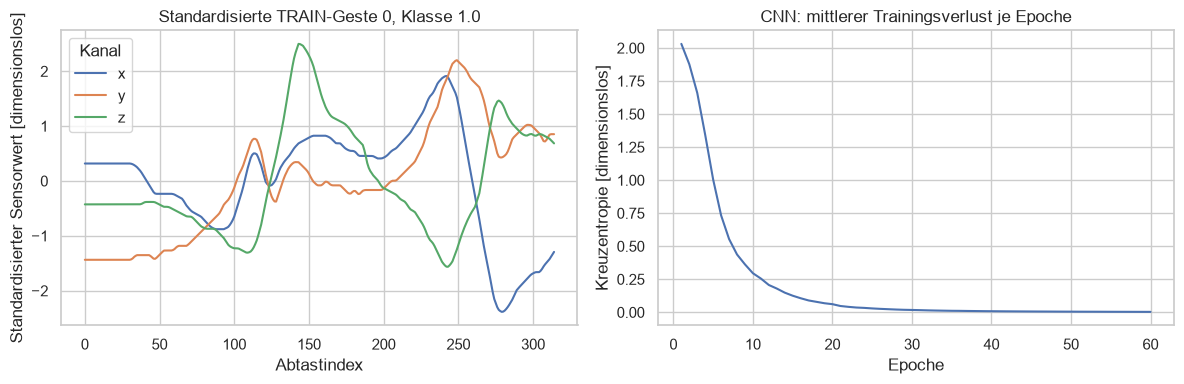

In [2]:
sns.set_theme(style="whitegrid")
fig,axes=plt.subplots(1,2,figsize=(12,4))
example=transform(x_train[:1],fitted["scaler"])[0]
for channel,name in enumerate(["x","y","z"]): axes[0].plot(example[channel],label=name)
axes[0].set(title=f"Standardisierte TRAIN-Geste 0, Klasse {y_train[0]}",xlabel="Abtastindex",ylabel="Standardisierter Sensorwert [dimensionslos]")
axes[0].legend(title="Kanal")
sns.lineplot(data=fitted["history"],x="epoch",y="train_cross_entropy",ax=axes[1])
axes[1].set(title="CNN: mittlerer Trainingsverlust je Epoche",xlabel="Epoche",ylabel="Kreuzentropie [dimensionslos]")
fig.tight_layout();fig.savefig(OUT/"01_input_and_training.png",dpi=150);plt.show()

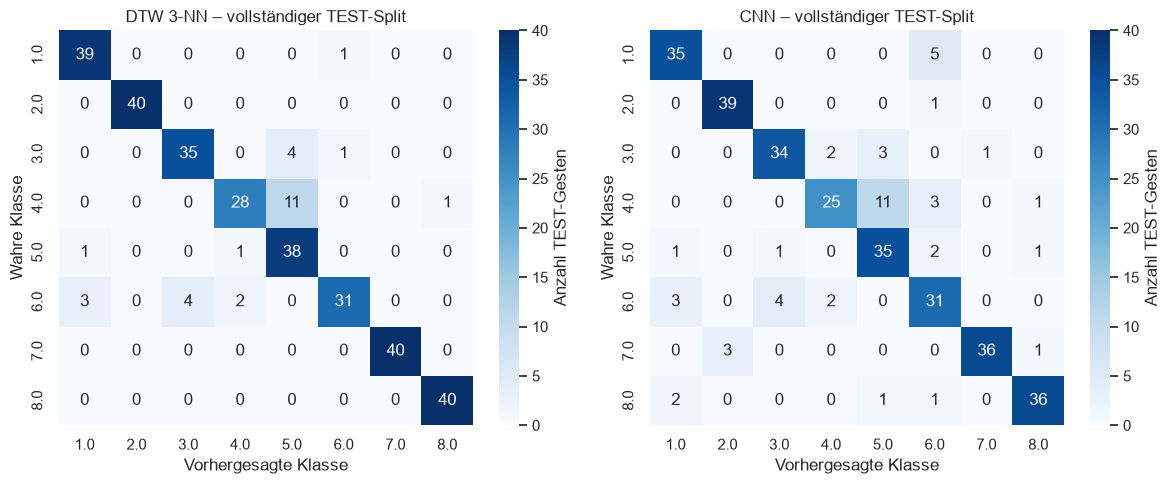

,method,class,precision,recall,f1-score,support
0,DTW 3-NN,1.0,0.9070,0.975,0.9398,40.0
1,DTW 3-NN,2.0,1.0000,1.000,1.0000,40.0
2,DTW 3-NN,3.0,0.8974,0.875,0.8861,40.0
3,DTW 3-NN,4.0,0.9032,0.700,0.7887,40.0
4,DTW 3-NN,5.0,0.7170,0.950,0.8172,40.0
5,DTW 3-NN,6.0,0.9394,0.775,0.8493,40.0
6,DTW 3-NN,7.0,1.0000,1.000,1.0000,40.0
7,DTW 3-NN,8.0,0.9756,1.000,0.9877,40.0
8,CNN,1.0,0.8537,0.875,0.8642,40.0
9,CNN,2.0,0.9286,0.975,0.9512,40.0


Accuracy-Differenz CNN minus kNN: -0.0625


In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(name,matrix) in zip(axes,matrices.items()):
    table=pd.DataFrame(matrix,index=fitted["classes"],columns=fitted["classes"])
    table.to_csv(OUT/("confusion_knn.csv" if name=="DTW 3-NN" else "confusion_cnn.csv"))
    sns.heatmap(table,annot=True,fmt="d",cmap="Blues",vmin=0,vmax=max(int(m.max()) for m in matrices.values()),ax=ax,cbar_kws={"label":"Anzahl TEST-Gesten"})
    ax.set(title=name+" – vollständiger TEST-Split",xlabel="Vorhergesagte Klasse",ylabel="Wahre Klasse")
fig.tight_layout();fig.savefig(OUT/"02_confusion_matrices.png",dpi=150);plt.show()
display(reports.round(4))
print("Accuracy-Differenz CNN minus kNN:",float(metrics.set_index("method").loc["CNN","accuracy"]-metrics.set_index("method").loc["DTW 3-NN","accuracy"]))

## Ergebnis und Grenzen
Accuracy ist der Anteil korrekter Testklassifikationen. Balanced Accuracy mittelt
den Recall über die acht Klassen; Macro-F1 gewichtet jede Klasse gleich.
Die Confusion-Matrizen besitzen dieselbe explizite Klassenreihenfolge; Zeilen
sind wahre und Spalten vorhergesagte Klassen. Die Diagonale zählt korrekte Fälle,
die Nebendiagonale zeigt Verwechslungen. Der Klassenbericht ergänzt Precision,
Recall, F1 und Support statt nur einen Gesamtwert zu betrachten.

In diesem Lauf klassifiziert DTW-3-NN 291 von 320 Fällen korrekt (90,9375 %),
das CNN 271 (84,6875 %). Macro-F1 beträgt etwa 0,9086 bzw. 0,8465; der Unterschied
der Accuracy liegt bei 6,25 Prozentpunkten zugunsten von DTW-3-NN. Die acht Testklassen
sind gleich häufig vertreten, daher stimmen Accuracy und Balanced Accuracy hier
überein. Die Confusion-Matrizen zeigen, auf welche Klassen sich die Fehler verteilen.
Beide Methoden verwechseln elf Gesten der Klasse 4.0 mit 5.0. kNN erkennt die
Klassen 7.0 und 8.0 jeweils vollständig (40/40), das CNN jeweils 36/40. Diese
Beobachtung beschreibt Fehlergruppen, ohne deren Ursache zu beweisen.
Daraus folgt keine allgemeine Überlegenheit von kNN über CNN.

Die tatsächlichen Zahlen und die Accuracy-Differenz stehen oben. Der Vergleich
gilt für diese Architektur, DTW-Einstellungen, 120 Trainingsfälle, einen Seed und
den vorgegebenen Split. CNN und DTW besitzen unterschiedliche Annahmen und Rechenkosten.
Ein fallender Trainingsverlust zeigt Optimierung auf TRAIN, keine Generalisierung
oder Kalibrierung der Vorhersagen. Eine gesonderte Validierungs-/Seed-Studie wurde
nicht durchgeführt; daher keine Aussage über optimale Hyperparameter oder Stabilität.
Die Testauswertung wird nicht zur nachträglichen Verbesserung dieser Modelle genutzt.

Die gemeinsame Trainingsstandardisierung erleichtert den fairen Vergleich, garantiert
aber keine perfekte Verteilungsübereinstimmung. Bei unbekannter Splitentstehung ist
personenunabhängige oder zeitlich zukünftige Generalisierung nicht bewiesen. Keine
kausale Erklärung einzelner Gestenfehler und keine allgemeine Überlegenheit einer
Methodenfamilie. Rohdaten und ältere Aufgaben bleiben unverändert.